In [1]:
import pandas as pd
import numpy as np
import re
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [2]:
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

# Pre-processing

In [3]:
df = pd.read_csv("Suicide_Detection (1).csv")

# Rename 'Unnamed' column
df = df.rename(columns={'Unnamed: 0': 'ID'})

# Drop rows with missing values in the 'class' column
df = df.dropna(subset=['class'])

In [4]:
def clean_text(text):
    text = re.sub(r'[^a-zA-Z\s]', '', text)  # Remove non-alphabetic characters
    text = ' '.join(text.split())  # Remove extra whitespaces
    return text

# Apply the cleaning function to the 'text' column
df['cleaned_text'] = df['text'].apply(clean_text)

# Tokenization
df['tokenized_text'] = df['cleaned_text'].apply(word_tokenize)

# Lowercasing
df['lowercased_text'] = df['tokenized_text'].apply(lambda x: [word.lower() for word in x])

# Removing stopwords
stop_words = set(stopwords.words('english'))
df['filtered_text'] = df['lowercased_text'].apply(lambda x: [word for word in x if word not in stop_words])

# Lemmatization
lemmatizer = WordNetLemmatizer()
df['lemmatized_text'] = df['filtered_text'].apply(lambda x: [lemmatizer.lemmatize(word) for word in x])


# Doc2Vec vectorization

In [5]:
model_w2v = Word2Vec(sentences=df['lemmatized_text'], vector_size=100, window=5, min_count=1, workers=4)

# Function to get document vectors
def get_doc_vector(tokens, model):
    vectors = [model.wv[word] for word in tokens if word in model.wv.index_to_key]
    return np.mean(vectors, axis=0) if vectors else np.zeros(model.vector_size)

# Get document vectors
df['doc_vector'] = df['lemmatized_text'].apply(lambda x: get_doc_vector(x, model_w2v))


In [6]:
df.head()

,ID,text,class,cleaned_text,tokenized_text,lowercased_text,filtered_text,lemmatized_text,doc_vector
0,2,Ex Wife Threatening SuicideRecently I left my ...,suicide,Ex Wife Threatening SuicideRecently I left my ...,"[Ex, Wife, Threatening, SuicideRecently, I, le...","[ex, wife, threatening, suiciderecently, i, le...","[ex, wife, threatening, suiciderecently, left,...","[ex, wife, threatening, suiciderecently, left,...","[0.83925074, 0.067517556, -0.7511661, -0.26687..."
1,3,Am I weird I don't get affected by compliments...,non-suicide,Am I weird I dont get affected by compliments ...,"[Am, I, weird, I, dont, get, affected, by, com...","[am, i, weird, i, dont, get, affected, by, com...","[weird, dont, get, affected, compliments, comi...","[weird, dont, get, affected, compliment, comin...","[0.60238886, 0.03218004, -0.6537581, -0.322702..."
2,4,Finally 2020 is almost over... So I can never ...,non-suicide,Finally is almost over So I can never hear has...,"[Finally, is, almost, over, So, I, can, never,...","[finally, is, almost, over, so, i, can, never,...","[finally, almost, never, hear, bad, year, ever...","[finally, almost, never, hear, bad, year, ever...","[0.96266764, 0.06472074, -0.9390524, -0.285378..."
3,8,i need helpjust help me im crying so hard,suicide,i need helpjust help me im crying so hard,"[i, need, helpjust, help, me, im, crying, so, ...","[i, need, helpjust, help, me, im, crying, so, ...","[need, helpjust, help, im, crying, hard]","[need, helpjust, help, im, cry, hard]","[0.76039535, -0.06543345, -0.29097697, 0.02986..."
4,9,"I’m so lostHello, my name is Adam (16) and I’v...",suicide,Im so lostHello my name is Adam and Ive been s...,"[Im, so, lostHello, my, name, is, Adam, and, I...","[im, so, losthello, my, name, is, adam, and, i...","[im, losthello, name, adam, ive, struggling, y...","[im, losthello, name, adam, ive, struggling, y...","[0.8041032, -0.059359383, -0.6926408, -0.28121..."


In [7]:
print(df['class'].unique())
# Create binary for class column
df['class_binary'] = df['class'].map({'suicide': 1, 'non-suicide': 0})

['suicide' 'non-suicide']


In [8]:
df.head()

,ID,text,class,cleaned_text,tokenized_text,lowercased_text,filtered_text,lemmatized_text,doc_vector,class_binary
0,2,Ex Wife Threatening SuicideRecently I left my ...,suicide,Ex Wife Threatening SuicideRecently I left my ...,"[Ex, Wife, Threatening, SuicideRecently, I, le...","[ex, wife, threatening, suiciderecently, i, le...","[ex, wife, threatening, suiciderecently, left,...","[ex, wife, threatening, suiciderecently, left,...","[0.83925074, 0.067517556, -0.7511661, -0.26687...",1
1,3,Am I weird I don't get affected by compliments...,non-suicide,Am I weird I dont get affected by compliments ...,"[Am, I, weird, I, dont, get, affected, by, com...","[am, i, weird, i, dont, get, affected, by, com...","[weird, dont, get, affected, compliments, comi...","[weird, dont, get, affected, compliment, comin...","[0.60238886, 0.03218004, -0.6537581, -0.322702...",0
2,4,Finally 2020 is almost over... So I can never ...,non-suicide,Finally is almost over So I can never hear has...,"[Finally, is, almost, over, So, I, can, never,...","[finally, is, almost, over, so, i, can, never,...","[finally, almost, never, hear, bad, year, ever...","[finally, almost, never, hear, bad, year, ever...","[0.96266764, 0.06472074, -0.9390524, -0.285378...",0
3,8,i need helpjust help me im crying so hard,suicide,i need helpjust help me im crying so hard,"[i, need, helpjust, help, me, im, crying, so, ...","[i, need, helpjust, help, me, im, crying, so, ...","[need, helpjust, help, im, crying, hard]","[need, helpjust, help, im, cry, hard]","[0.76039535, -0.06543345, -0.29097697, 0.02986...",1
4,9,"I’m so lostHello, my name is Adam (16) and I’v...",suicide,Im so lostHello my name is Adam and Ive been s...,"[Im, so, lostHello, my, name, is, Adam, and, I...","[im, so, losthello, my, name, is, adam, and, i...","[im, losthello, name, adam, ive, struggling, y...","[im, losthello, name, adam, ive, struggling, y...","[0.8041032, -0.059359383, -0.6926408, -0.28121...",1


In [13]:
df.isnull().sum()

ID                 0
text               0
class              0
cleaned_text       0
tokenized_text     0
lowercased_text    0
filtered_text      0
lemmatized_text    0
doc_vector         0
class_binary       0
dtype: int64

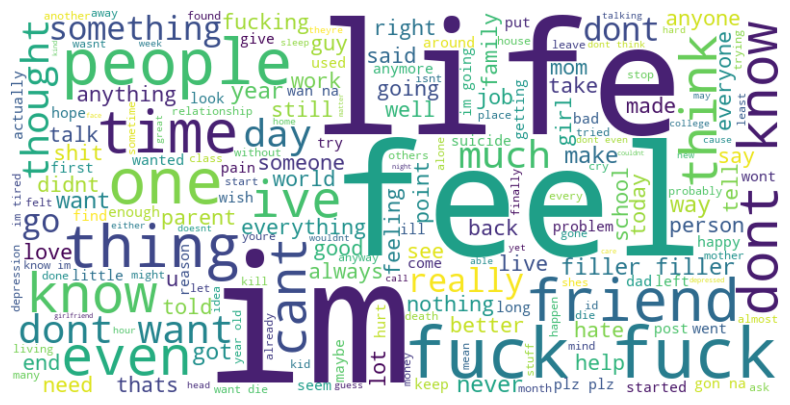

In [15]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Concatenate all lemmatized text into a single string
all_text = ' '.join([' '.join(tokens) for tokens in df['lemmatized_text']])

# Generate a word cloud
wordcloud = WordCloud(width=800, height=400, random_state=42, background_color='white').generate(all_text)

# Display the generated word cloud using matplotlib
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()


# Applying Logistic Regression

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    np.vstack(df['doc_vector']), df['class_binary'], test_size=0.2, random_state=42
)

# Logistic Regression
logreg = LogisticRegression()
logreg.fit(X_train, y_train)

# Predictions
y_pred = logreg.predict(X_test)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test,y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print(f'Accuracy: {accuracy:.2f}')
print(f'Precision: {precision:.2f}')
print(f'Recall: {recall:.2f}')
print(f'F1 Score: {f1:.2f}')
print('Confusion Matrix:')
print(conf_matrix)

Accuracy: 0.87
Precision: 0.86
Recall: 0.88
F1 Score: 0.87
Confusion Matrix:
[[639 110]
 [ 91 664]]


C:\Users\Admin\nidcatpythonlab\Lib\site-packages\sklearn\linear_model\_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


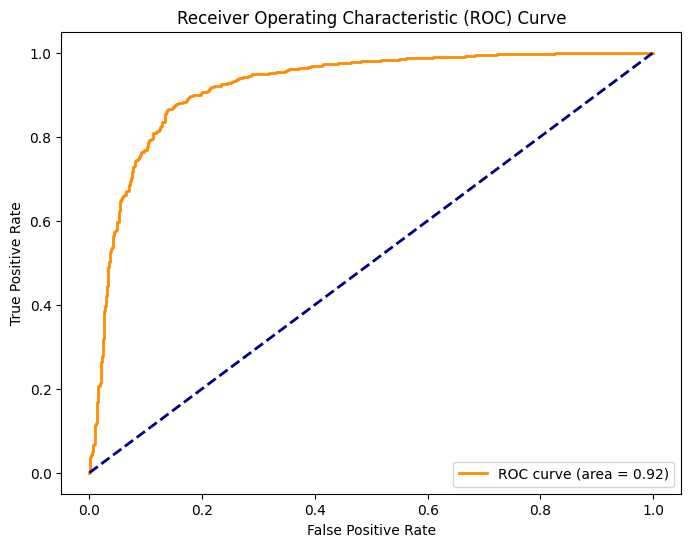

In [27]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Assuming logreg is already trained as per your previous code
y_scores = logreg.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_scores)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()


# Applying a Recurrent Neural Network

In [10]:
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, SpatialDropout1D
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Function to get sequences from Word2Vec vectors
def get_sequences(tokens, model):
    sequences = [model.wv[word] for word in tokens if word in model.wv.index_to_key]
    return sequences

# Get sequences
df['word2vec_sequences'] = df['lemmatized_text'].apply(lambda x: get_sequences(x, model_w2v))

max_len = 50
# Pad sequences to a fixed length
X_word2vec = pad_sequences(df['word2vec_sequences'], maxlen=max_len, dtype='float32')

# Split the data into training and testing sets
X_train_word2vec, X_test_word2vec, y_train_word2vec, y_test_word2vec = train_test_split(
    X_word2vec, df['class_binary'], test_size=0.2, random_state=42
)

# Build the RNN model
embedding_dim = 100  # Dimension of word embeddings
model = Sequential()
model.add(LSTM(80, input_shape=(max_len, embedding_dim)))
model.add(Dense(1, activation='sigmoid'))

# Compile the model
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# Train the model
epochs = 5
batch_size = 32
history = model.fit(X_train_word2vec, y_train_word2vec, epochs=epochs, batch_size=batch_size, validation_split=0.2)

# Evaluate the model on the test set
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test,y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print(f'Accuracy: {accuracy:.2f}')
print(f'Precision: {precision:.2f}')
print(f'Recall: {recall:.2f}')
print(f'F1 Score: {f1:.2f}')
print('Confusion Matrix:')
print(conf_matrix)




Epoch 1/5


151/151 [==============================] - 7s 31ms/step - loss: 0.3800 - accuracy: 0.8352 - val_loss: 0.3212 - val_accuracy: 0.8646
Epoch 2/5
151/151 [==============================] - 4s 28ms/step - loss: 0.3218 - accuracy: 0.8691 - val_loss: 0.3358 - val_accuracy: 0.8638
Epoch 3/5
151/151 [==============================] - 5s 33ms/step - loss: 0.2982 - accuracy: 0.8770 - val_loss: 0.3690 - val_accuracy: 0.8488
Epoch 4/5
151/151 [==============================] - 4s 29ms/step - loss: 0.2971 - accuracy: 0.8809 - val_loss: 0.2857 - val_accuracy: 0.8821
Epoch 5/5
151/151 [==============================] - 4s 28ms/step - loss: 0.2841 - accuracy: 0.8853 - val_loss: 0.2880 - val_accuracy: 0.8746
Accuracy: 0.87
Precision: 0.86
Recall: 0.88
F1 Score: 0.87
Confusion Matrix:
[[639 110]
 [ 91 664]]


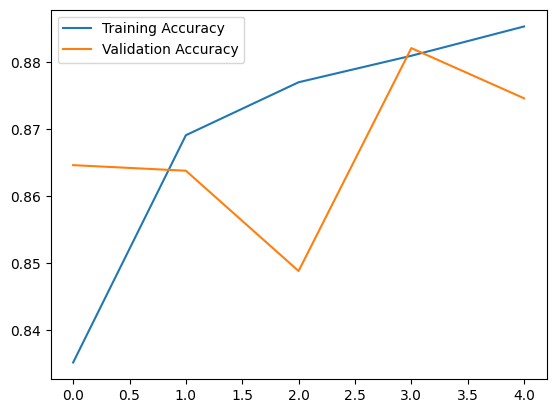

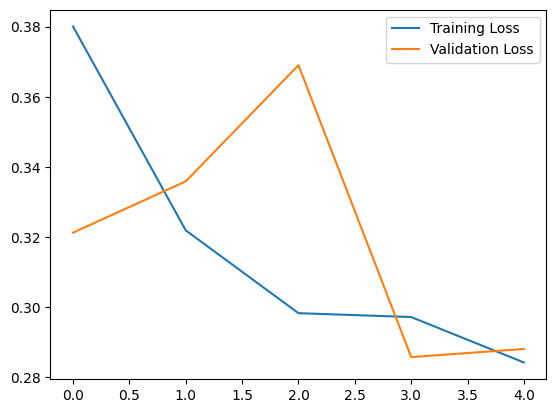

In [12]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.show()

# Plot training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.show()